In [ ]:
!pip install yfinance statemodels scikit-learn

ERROR: Could not find a version that satisfies the requirement statemodels (from versions: none)
ERROR: No matching distribution found for statemodels


In [ ]:
%pip install -U statsmodels scikit-learn

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels
import sklearn
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:

import yfinance as yf
import pandas as pd

ticker = "RELIANCE.NS"

data = yf.download(
    ticker,
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("Data download nahi hua. Internet ya ticker check karo.")

if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data.sort_index()
data = data[~data.index.duplicated(keep="last")]


print("Data downloaded successfully!")
print("Stock:", ticker)
print("Start Date:", data.index.min().date())
print("End Date:", data.index.max().date())
print("Total Trading Days:", len(data))

display(data.head())

Data downloaded successfully!
Stock: RELIANCE.NS
Start Date: 2021-10-11
End Date: 2026-10-09
Total Trading Days: 1236


Price,Close,High,Low,Open,Volume
Date,,,,,
2021-10-11,1201.432739,1231.936779,1198.126490,1223.512540,14768666
2021-10-12,1208.294434,1215.178880,1196.269475,1197.968004,6682011
2021-10-13,1220.591064,1231.710211,1208.973668,1213.366985,9959762
2021-10-14,1223.059448,1230.781777,1217.080933,1223.036806,8623469
2021-10-18,1226.320557,1243.259604,1205.803314,1208.656718,13594479


Data prepared successfully!
Stock: RELIANCE.NS
Total observations: 1236
Start date: 2021-10-11
End date: 2026-10-09
Missing values: 0

First 5 observations:


,Close
Date,
2021-10-11,1201.432739
2021-10-12,1208.294434
2021-10-13,1220.591064
2021-10-14,1223.059448
2021-10-18,1226.320557


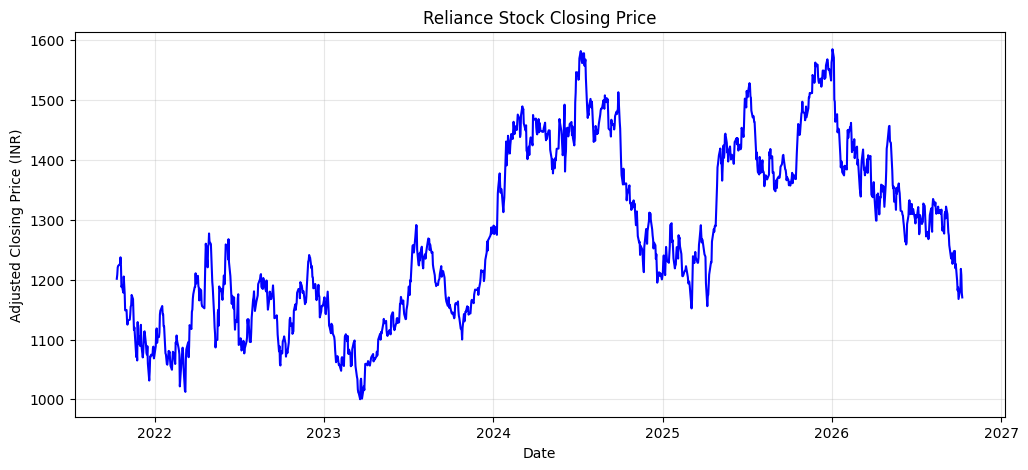

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

close = data["Close"].copy()

close = pd.to_numeric(close, errors="coerce")

close = close.replace([np.inf, -np.inf], np.nan)
close = close.dropna()

close = close.sort_index()

close = close[~close.index.duplicated(keep="last")]

print("Data prepared successfully!")
print("Stock: RELIANCE.NS")
print("Total observations:", len(close))
print("Start date:", close.index.min().date())
print("End date:", close.index.max().date())
print("Missing values:", close.isnull().sum())

print("\nFirst 5 observations:")
display(close.head())

plt.figure(figsize=(12, 5))
plt.plot(close.index, close.values, color="blue")
plt.title("Reliance Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
split_index = int(len(close) * 0.80)

train = close.iloc[:split_index]
test = close.iloc[split_index:]

print("Total data:", len(close))
print("Training data:", len(train))
print("Testing data:", len(test))

print("\nTraining period:")
print(train.index.min().date(), "to", train.index.max().date())

print("\nTesting period:")
print(test.index.min().date(), "to", test.index.max().date())

Total data: 1236
Training data: 988
Testing data: 248

Training period:
2021-10-11 to 2025-10-08

Testing period:
2025-10-09 to 2026-10-09


In [ ]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train.dropna())

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))

if adf_result[1] < 0.05:
    print("Result: Data stationary hai.")
else:
    print("Result: Data non-stationary ho sakta hai.")

ADF Statistic: -1.9103
p-value: 0.327219
Result: Data non-stationary ho sakta hai.


/tmp/ipykernel_5323/281405890.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train.dropna())


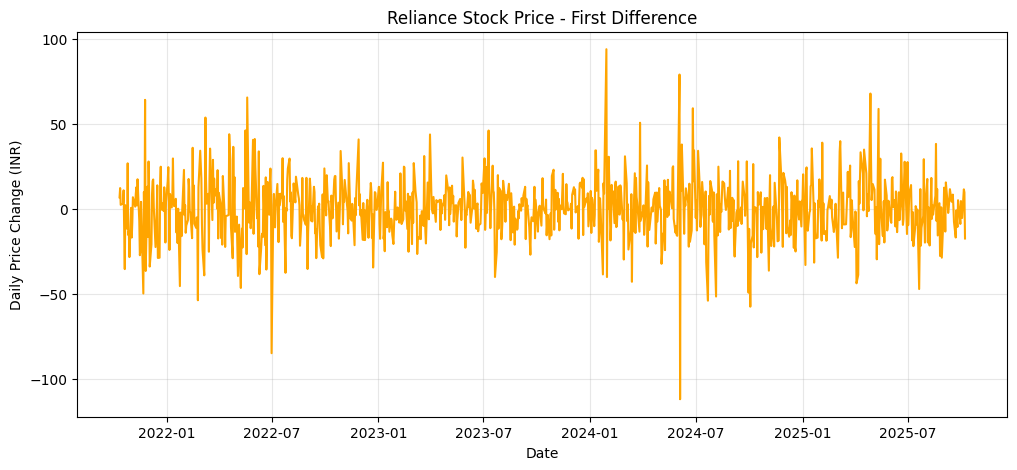

Differenced data p-value: 0.0
First difference stationary hai; d = 1 ek reasonable choice hai.


/tmp/ipykernel_5323/1507849517.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff_result = adfuller(train_diff)


In [ ]:
train_diff = train.diff().dropna()

plt.figure(figsize=(12, 5))
plt.plot(train_diff.index, train_diff.values, color="orange")
plt.title("Reliance Stock Price - First Difference")
plt.xlabel("Date")
plt.ylabel("Daily Price Change (INR)")
plt.grid(True, alpha=0.3)
plt.show()

diff_result = adfuller(train_diff)

print("Differenced data p-value:",
      round(diff_result[1], 6))

if diff_result[1] < 0.05:
    print("First difference stationary hai; d = 1 ek reasonable choice hai.")
else:
    print("First difference bhi non-stationary ho sakta hai.")

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

p = 1
d = 1
q = 1

model = ARIMA(train, order=(p, d, q))

model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/p

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                  988
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4231.555
Date:                Sat, 10 Oct 2026   AIC                           8469.109
Time:                        12:40:07   BIC                           8483.793
Sample:                             0   HQIC                          8474.694
                                - 988                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8461      0.161     -5.266      0.000      -1.161      -0.531
ma.L1          0.8160      0.172      4.733      0.000       0.478       1.154
sigma2       310.0339      8.873     34.940      0.0

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

close = close.copy()
close.index = pd.to_datetime(close.index)
close = close.sort_index()
close = close[~close.index.duplicated(keep="last")]
close = close.astype(float).dropna()

close = close.asfreq("B").ffill()

split_index = int(len(close) * 0.80)
train = close.iloc[:split_index]
test = close.iloc[split_index:]

print("Training data:", len(train))
print("Testing data:", len(test))
print("Index type:", type(train.index))
print("Frequency:", train.index.freq)

Training data: 1044
Testing data: 261
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Frequency: <BusinessDay>


In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

train_arima = pd.Series(
    train.to_numpy(dtype=float),
    index=pd.RangeIndex(len(train))
)

model = ARIMA(train_arima, order=(1, 1, 1))
model_fit = model.fit()

forecast_values = model_fit.forecast(steps=len(test))
forecast_values = np.asarray(forecast_values).reshape(-1)

forecast = pd.Series(
    forecast_values,
    index=test.index,
    name="Predicted Price"
)

print("Forecast generated successfully!")
display(forecast.head())

Forecast generated successfully!


,Predicted Price
Date,
2025-10-10,1370.897140
2025-10-13,1371.253197
2025-10-14,1371.027554
2025-10-15,1371.170550
2025-10-16,1371.079929


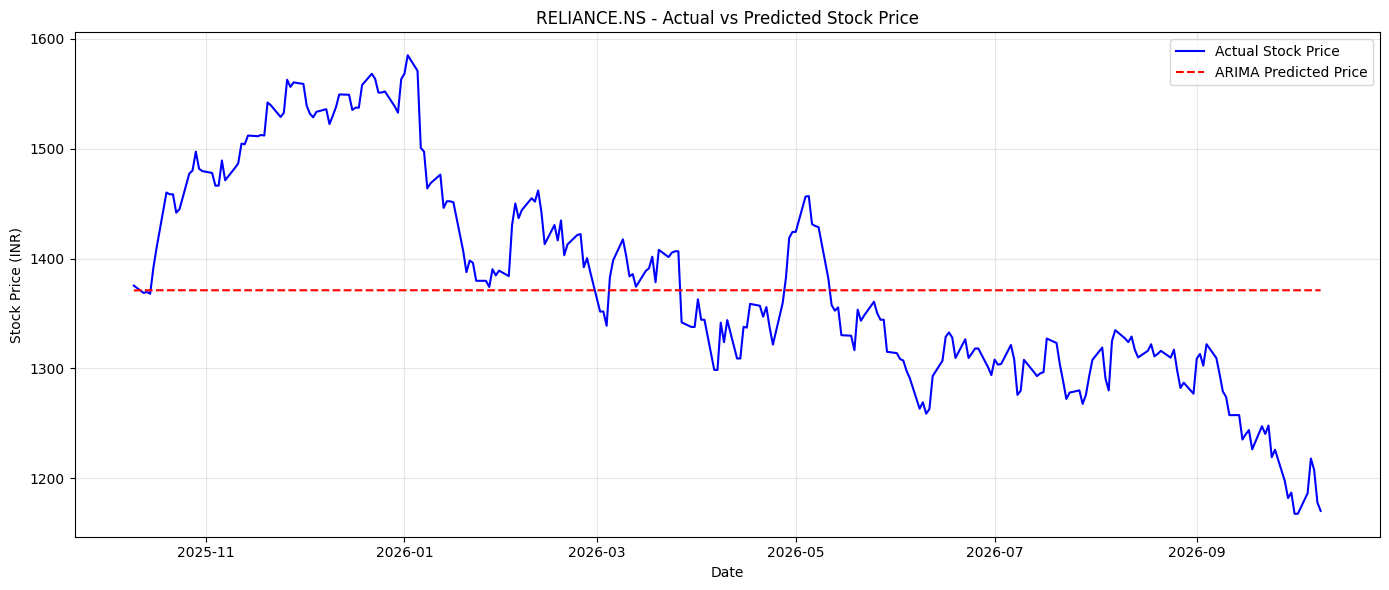

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    color="blue",
    label="Actual Stock Price"
)

plt.plot(
    forecast.index,
    forecast.values,
    color="red",
    linestyle="--",
    label="ARIMA Predicted Price"
)

plt.title("RELIANCE.NS - Actual vs Predicted Stock Price")
plt.xlabel("Date")
plt.ylabel("Stock Price (INR)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(mean_squared_error(test, forecast))

mape = np.mean(
    np.abs((test.to_numpy() - forecast.to_numpy()) / test.to_numpy())
) * 100

print("ARIMA Model Evaluation")
print("----------------------")
print(f"MAE  : Rs. {mae:.2f}")
print(f"RMSE : Rs. {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

ARIMA Model Evaluation
----------------------
MAE  : Rs. 80.65
RMSE : Rs. 97.57
MAPE : 5.82%


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

all_prices = pd.Series(
    close.to_numpy(dtype=float),
    index=pd.RangeIndex(len(close))
)

final_model = ARIMA(all_prices, order=(1, 1, 1))
final_model_fit = final_model.fit()

steps = 30
future_forecast = final_model_fit.forecast(steps=steps)

future_dates = pd.bdate_range(
    start=close.index[-1] + pd.Timedelta(days=1),
    periods=steps
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecasted_Price": np.asarray(future_forecast)
})

print("Future Forecast Generated Successfully!")
display(forecast_df.round(2))

Future Forecast Generated Successfully!


,Date,Forecasted_Price
0,2026-10-12,1170.27
1,2026-10-13,1170.29
2,2026-10-14,1170.28
3,2026-10-15,1170.29
4,2026-10-16,1170.28
5,2026-10-19,1170.29
6,2026-10-20,1170.28
7,2026-10-21,1170.28
8,2026-10-22,1170.28
9,2026-10-23,1170.28


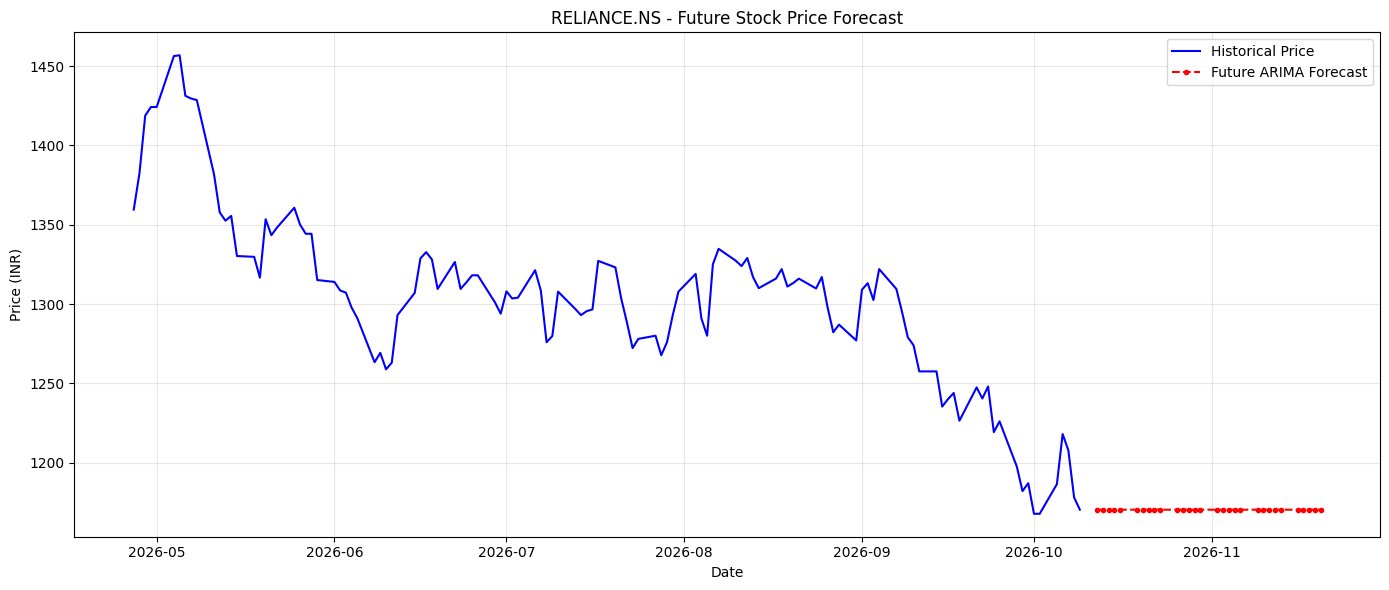

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    close.index[-120:],
    close.iloc[-120:],
    label="Historical Price",
    color="blue"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Forecasted_Price"],
    label="Future ARIMA Forecast",
    color="red",
    linestyle="--",
    marker="o",
    markersize=3
)

plt.title("RELIANCE.NS - Future Stock Price Forecast")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
forecast_df.to_csv("reliance_future_forecast.csv", index=False)

print("Forecast saved successfully!")

Forecast saved successfully!


In [ ]:
from google.colab import files

files.download("reliance_future_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Column Names:")
print(forecast_df.columns.tolist())

print("\nForecast Data:")
display(forecast_df.head(10))

print("\nTotal Rows and Columns:")
print(forecast_df.shape)

Column Names:
['Date', 'Forecasted_Price']

Forecast Data:


,Date,Forecasted_Price
0,2026-10-12,1170.274386
1,2026-10-13,1170.290241
2,2026-10-14,1170.280446
3,2026-10-15,1170.286497
4,2026-10-16,1170.282758
5,2026-10-19,1170.285069
6,2026-10-20,1170.283641
7,2026-10-21,1170.284523
8,2026-10-22,1170.283978
9,2026-10-23,1170.284315



Total Rows and Columns:
(30, 2)


In [ ]:
print("RELIANCE.NS - ARIMA Model Results")
print("---------------------------------")
print(f"MAE  : Rs. {mae:.2f}")
print(f"RMSE : Rs. {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

RELIANCE.NS - ARIMA Model Results
---------------------------------
MAE  : Rs. 80.65
RMSE : Rs. 97.57
MAPE : 5.82%


In [ ]:
import pandas as pd
clean_data = data.copy()

print("Total rows:", len(clean_data))
print("Total columns:", len(clean_data.columns))
print("Missing values in each column:")
print(clean_data.isna().sum())

print("Duplicate dates:", clean_data.index.duplicated().sum())

display(clean_data.head())

NameError: name 'data' is not defined

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ticker = "RELIANCE.NS"

data = yf.download(
    ticker,
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

print("Data downloaded:", not data.empty)
print("Total rows:", len(data))
display(data.head())

Data downloaded: True
Total rows: 1236


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2021-10-11,1201.432617,1231.936654,1198.126368,1223.512415,14768666
2021-10-12,1208.294312,1215.178757,1196.269354,1197.967883,6682011
2021-10-13,1220.591064,1231.710211,1208.973668,1213.366985,9959762
2021-10-14,1223.059570,1230.781900,1217.081054,1223.036928,8623469
2021-10-18,1226.320557,1243.259604,1205.803314,1208.656718,13594479


In [ ]:
import pandas as pd
clean_data = data.copy()

print("Total rows:", len(clean_data))
print("Total columns:", len(clean_data.columns))
print("Missing values in each column:")
print(clean_data.isna().sum())

print("Duplicate dates:", clean_data.index.duplicated().sum())

display(clean_data.head())

Total rows: 1236
Total columns: 5
Missing values in each column:
Price   Ticker     
Close   RELIANCE.NS    0
High    RELIANCE.NS    0
Low     RELIANCE.NS    0
Open    RELIANCE.NS    0
Volume  RELIANCE.NS    0
dtype: int64
Duplicate dates: 0


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2021-10-11,1201.432617,1231.936654,1198.126368,1223.512415,14768666
2021-10-12,1208.294312,1215.178757,1196.269354,1197.967883,6682011
2021-10-13,1220.591064,1231.710211,1208.973668,1213.366985,9959762
2021-10-14,1223.059570,1230.781900,1217.081054,1223.036928,8623469
2021-10-18,1226.320557,1243.259604,1205.803314,1208.656718,13594479


In [ ]:
print("Total rows:", len(clean_data))
print("Total columns:", len(clean_data.columns))

print("\nDuplicate dates:", clean_data.index.duplicated().sum())

Total rows: 1236
Total columns: 5

Duplicate dates: 0


In [ ]:

close_data = clean_data["Close"]

if isinstance(close_data, pd.DataFrame):
    close_data = close_data.iloc[:, 0]

close_data = pd.to_numeric(close_data, errors="coerce")
close_data = close_data.dropna().sort_index()

returns = close_data.pct_change().dropna()

print("First date:", close_data.index.min().date())
print("Last date:", close_data.index.max().date())
print("Total observations:", len(close_data))
print("Average closing price: ₹", round(close_data.mean(), 2))
print("Minimum closing price: ₹", round(close_data.min(), 2))
print("Maximum closing price: ₹", round(close_data.max(), 2))
print("Average daily return (%):", round(returns.mean() * 100, 4))
print("Daily return volatility (%):", round(returns.std() * 100, 4))


First date: 2021-10-11
Last date: 2026-10-09
Total observations: 1236
Average closing price: ₹ 1274.59
Minimum closing price: ₹ 1000.24
Maximum closing price: ₹ 1584.97
Average daily return (%): 0.0077
Daily return volatility (%): 1.4058


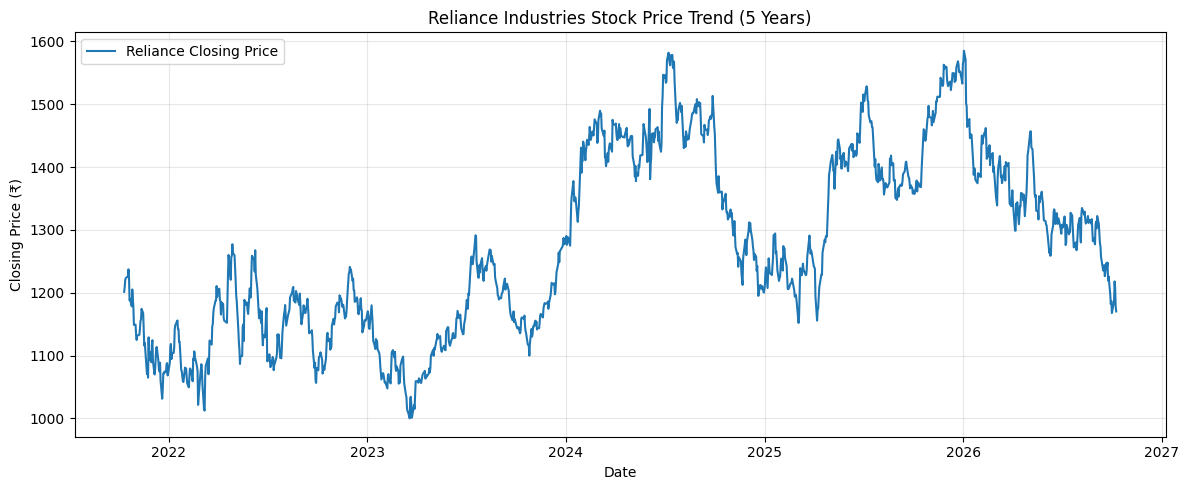

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(close_data.index, close_data.values, label="Reliance Closing Price")

plt.title("Reliance Industries Stock Price Trend (5 Years)")
plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


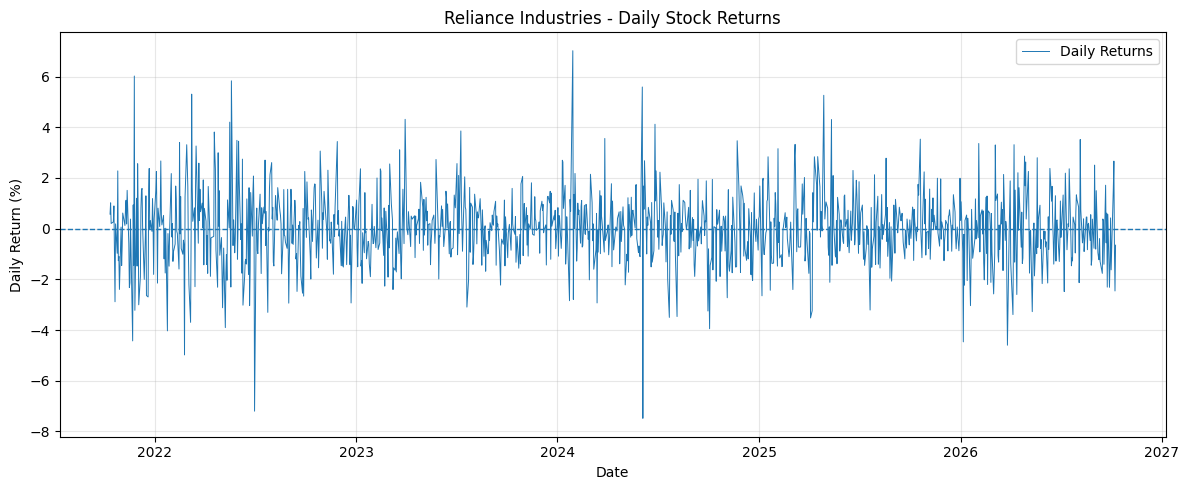

Daily return observations: 1235
Average daily return (%): 0.0077
Daily return volatility (%): 1.4058


In [ ]:

daily_returns = close_data.pct_change().dropna() * 100

plt.figure(figsize=(12, 5))
plt.plot(daily_returns.index, daily_returns.values,
         label="Daily Returns", linewidth=0.7)

plt.title("Reliance Industries - Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Daily return observations:", len(daily_returns))
print("Average daily return (%):", round(daily_returns.mean(), 4))
print("Daily return volatility (%):", round(daily_returns.std(), 4))


In [ ]:

print("Model available:", "model_fit" in globals())
print("Train data available:", "train" in globals())
print("Test data available:", "test" in globals())


Model available: False
Train data available: False
Test data available: False


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

print("Libraries ready!")
print("Stock data available:", "data" in globals())
print("Cleaned data available:", "clean_data" in globals())


Libraries ready!
Stock data available: True
Cleaned data available: True


In [ ]:

close_data = clean_data["Close"]

if isinstance(close_data, pd.DataFrame):
    close_data = close_data.iloc[:, 0]

close_data = pd.to_numeric(close_data, errors="coerce")
close_data = close_data.dropna().sort_index()

split_point = int(len(close_data) * 0.8)

train = close_data.iloc[:split_point]
test = close_data.iloc[split_point:]

print("Total observations:", len(close_data))
print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Missing values:", close_data.isna().sum())


Total observations: 1236
Training observations: 988
Testing observations: 248
Missing values: 0


In [ ]:

model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

print("ARIMA model trained successfully!")
print(model_fit.summary())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/p

ARIMA model trained successfully!
                               SARIMAX Results                                
Dep. Variable:            RELIANCE.NS   No. Observations:                  988
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4231.555
Date:                Sat, 10 Oct 2026   AIC                           8469.109
Time:                        15:40:00   BIC                           8483.793
Sample:                             0   HQIC                          8474.693
                                - 988                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8462      0.161     -5.271      0.000      -1.161      -0.532
ma.L1          0.8160      0.172      4.736      0.000       0.478       1.154
sigma2       310.0

In [ ]:

forecast_values = model_fit.get_forecast(
    steps=len(test)
).predicted_mean

predictions = pd.Series(
    np.asarray(forecast_values).reshape(-1),
    index=test.index,
    name="Predicted Price"
)

print("Predictions generated:", len(predictions))
print(predictions.head())


ValueError: No supported index is available.

In [ ]:

print("Model type:", type(model_fit))
print("Train length:", len(train))
print("Test length:", len(test))
print("Model index:", model_fit.model._index)


Model type: <class 'statsmodels.tsa.arima.model.ARIMAResultsWrapper'>
Train length: 988
Test length: 248
Model index: RangeIndex(start=0, stop=988, step=1)


In [ ]:

try:
    forecast_values = model_fit.get_forecast(
        steps=len(test)
    ).predicted_mean

    forecast_array = np.asarray(forecast_values).reshape(-1)

    print("Forecast successful!")
    print("Forecast length:", len(forecast_array))
    print("First 5 predictions:", forecast_array[:5])

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))


Error type: ValueError
Error message: No supported index is available.


In [ ]:

print("Forecast values available:", "forecast_values" in globals())
print("Predictions available:", "predictions" in globals())


Forecast values available: False
Predictions available: False


In [ ]:

print("Model type:", type(model_fit))
print("Model data type:", type(train))
print("Train index type:", type(train.index))
print("Train index start:", train.index[:3])
print("Model index:", model_fit.model._index)


Model type: <class 'statsmodels.tsa.arima.model.ARIMAResultsWrapper'>
Model data type: <class 'pandas.core.series.Series'>
Train index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Train index start: DatetimeIndex(['2021-10-11', '2021-10-12', '2021-10-13'], dtype='datetime64[ns]', name='Date', freq=None)
Model index: RangeIndex(start=0, stop=988, step=1)


In [ ]:

print("Statsmodels version:")
import statsmodels
print(statsmodels.__version__)

print("\nModel class:")
print(type(model_fit))

print("\nModel index:")
print(model_fit.model._index)


Statsmodels version:
0.15.0

Model class:
<class 'statsmodels.tsa.arima.model.ARIMAResultsWrapper'>

Model index:
RangeIndex(start=0, stop=988, step=1)


In [ ]:

print("Close data index type:", type(close_data.index))
print("First 3 dates:", close_data.index[:3])
print("Last 3 dates:", close_data.index[-3:])


Close data index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
First 3 dates: DatetimeIndex(['2021-10-11', '2021-10-12', '2021-10-13'], dtype='datetime64[ns]', name='Date', freq=None)
Last 3 dates: DatetimeIndex(['2026-10-07', '2026-10-08', '2026-10-09'], dtype='datetime64[ns]', name='Date', freq=None)


In [ ]:

train = close_data.iloc[:988].copy()
test = close_data.iloc[988:].copy()

model = ARIMA(
    train.astype(float),
    order=(1, 1, 1),
    dates=train.index
)

model_fit = model.fit()

print("Model retrained with date index!")
print("Training rows:", len(train))
print("Testing rows:", len(test))


ValueError: No frequency information was provided with date index and no frequency could be inferred.

In [ ]:

train = close_data.iloc[:988].copy()
test = close_data.iloc[988:].copy()

model = ARIMA(
    train.astype(float).to_numpy(),
    order=(1, 1, 1)
)

model_fit = model.fit()

print("ARIMA model trained successfully!")
print("Training rows:", len(train))
print("Testing rows:", len(test))


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA model trained successfully!
Training rows: 988
Testing rows: 248


In [ ]:

forecast_values = model_fit.forecast(steps=len(test))

predictions = pd.Series(
    np.asarray(forecast_values).reshape(-1),
    index=test.index,
    name="Predicted Price"
)

print("Predictions generated:", len(predictions))
print("\nFirst 5 predicted prices:")
print(predictions.head())


Predictions generated: 248

First 5 predicted prices:
Date
2025-10-09    1361.456786
2025-10-10    1361.160638
2025-10-13    1361.411238
2025-10-14    1361.199181
2025-10-15    1361.378623
Name: Predicted Price, dtype: float64


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


Model Evaluation Results
------------------------
MAE: 80.65
RMSE: 98.97


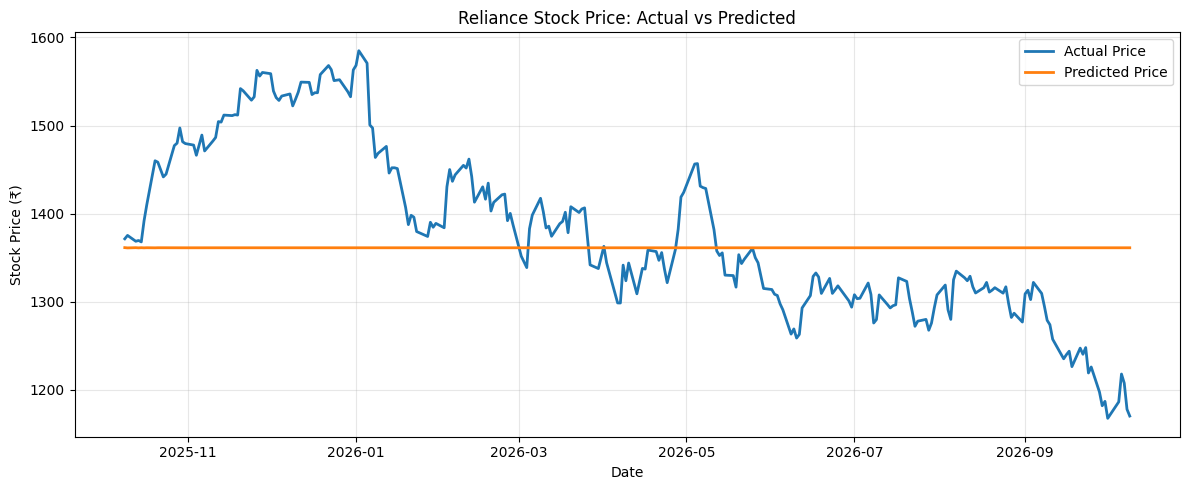

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(test.index, test.values,
         label="Actual Price", linewidth=2)

plt.plot(predictions.index, predictions.values,
         label="Predicted Price", linewidth=2)

plt.title("Reliance Stock Price: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

baseline_predictions = np.full(
    len(test),
    float(train.iloc[-1])
)

baseline_mae = mean_absolute_error(
    test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_predictions)
)

print("Baseline Model Results")
print("----------------------")
print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

print("\nARIMA Model Results")
print("-------------------")
print("ARIMA MAE:", round(mae, 2))
print("ARIMA RMSE:", round(rmse, 2))


Baseline Model Results
----------------------
Baseline MAE: 80.65
Baseline RMSE: 99.0

ARIMA Model Results
-------------------
ARIMA MAE: 80.65
ARIMA RMSE: 98.97


In [ ]:

naive_predictions = test.shift(1)

naive_predictions.iloc[0] = train.iloc[-1]

naive_mae = mean_absolute_error(test, naive_predictions)
naive_rmse = np.sqrt(mean_squared_error(test, naive_predictions))

print("Naive Baseline Results")
print("----------------------")
print("Naive MAE:", round(naive_mae, 2))
print("Naive RMSE:", round(naive_rmse, 2))

print("\nARIMA Results")
print("-------------")
print("ARIMA MAE:", round(mae, 2))
print("ARIMA RMSE:", round(rmse, 2))


Naive Baseline Results
----------------------
Naive MAE: 13.77
Naive RMSE: 18.31

ARIMA Results
-------------
ARIMA MAE: 80.65
ARIMA RMSE: 98.97


In [ ]:
readme = """
# Reliance Stock Price Forecasting Using Time Series Analysis

## Project Overview
This project analyzes five years of Reliance Industries stock data using Python and time series analysis.

## Tools
Python, Pandas, NumPy, Matplotlib, yfinance, Statsmodels, Scikit-learn.

## Workflow
1. Collected historical stock data.
2. Cleaned the dataset.
3. Performed exploratory data analysis.
4. Split data into training and testing sets.
5. Built an ARIMA(1,1,1) model.
6. Evaluated the model using MAE and RMSE.

## Results
- ARIMA MAE: ₹80.65
- ARIMA RMSE: ₹98.97
- Naive baseline MAE: ₹13.77
- Naive baseline RMSE: ₹18.31

## Conclusion
This project demonstrates data cleaning, exploratory data analysis, time series forecasting, visualization, and model evaluation.

Note: The baseline and ARIMA results use different forecasting approaches, so their errors should be compared carefully. This project is for educational purposes only.
"""

print(readme)


# Reliance Stock Price Forecasting Using Time Series Analysis

## Project Overview
This project analyzes five years of Reliance Industries stock data using Python and time series analysis.

## Tools
Python, Pandas, NumPy, Matplotlib, yfinance, Statsmodels, Scikit-learn.

## Workflow
1. Collected historical stock data.
2. Cleaned the dataset.
3. Performed exploratory data analysis.
4. Split data into training and testing sets.
5. Built an ARIMA(1,1,1) model.
6. Evaluated the model using MAE and RMSE.

## Results
- ARIMA MAE: ₹80.65
- ARIMA RMSE: ₹98.97
- Naive baseline MAE: ₹13.77
- Naive baseline RMSE: ₹18.31

## Conclusion
This project demonstrates data cleaning, exploratory data analysis, time series forecasting, visualization, and model evaluation.

Note: The baseline and ARIMA results use different forecasting approaches, so their errors should be compared carefully. This project is for educational purposes only.

